In [13]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt


In [14]:
dataset=pd.read_csv('cardio_dataset.csv').values

In [15]:
data=dataset[:,0:7]
target=dataset[:,7]

In [28]:
from sklearn.preprocessing import MinMaxScaler #scalling(take all variable inside one common range)

target=np.reshape(target, (-1,1))

scaler_data = MinMaxScaler(feature_range=(0,1)) #create object for scalling #feature range we can decide, bydefault (0,1)
scaler_target = MinMaxScaler()

data_scaled=scaler_data.fit_transform(data)
target_scaled=scaler_target.fit_transform(target)

print(scaler_data)
print(scaler_target)

print(data_scaled)

MinMaxScaler()
MinMaxScaler()
[[1.         0.20512821 0.40045249 ... 0.         1.         0.        ]
 [0.         0.20512821 0.45475113 ... 0.         1.         1.        ]
 [0.         0.1025641  0.28959276 ... 1.         1.         0.        ]
 ...
 [0.         0.64102564 0.34615385 ... 1.         0.         0.        ]
 [0.         0.66666667 0.28280543 ... 0.         0.         0.        ]
 [1.         0.12820513 0.32579186 ... 0.         1.         0.        ]]


In [17]:
from sklearn.model_selection import train_test_split

train_data, test_data, train_target, test_target = train_test_split(data_scaled, target_scaled,test_size=0.2)

In [18]:
from keras.models import Sequential
from keras.layers import Dense,Dropout
import numpy as np

model = Sequential()
model.add(Dense(128, input_dim=7, activation='sigmoid',kernel_initializer='normal'))
model.add(Dropout(0.5))
model.add(Dense(64, activation='sigmoid'))
model.add(Dropout(0.5))
model.add(Dense(10, activation='sigmoid'))
model.add(Dense(1, activation='linear'))

model.compile(optimizer='adam',loss='mse',metrics=['mse','mae'])

model.summary()

C:\Users\Kavindya\anaconda3\envs\dl_env\lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 128)                 │           1,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 10)                  │             650 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │              11 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 9,941 (38.83 KB)

 Trainable params: 9,941 (38.83 KB)

 Non-trainable params: 0 (0.00 B)

In [25]:
from sklearn.metrics import r2_score
import keras

class CustomCallback(keras.callbacks.Callback):  #create a class to print r2 endof each and every epoch
    
    def on_epoch_end(self,epoch,logs=None):
        predicted_result=model.predict(test_data)
        r2=r2_score(test_target,predicted_result)
        print('epoch ',epoch,'- r2 score:',r2)

In [21]:
from keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint('models/model-{epoch:03d}.keras',monitor='val_loss',save_best_only=True,mode='auto') #save only best W&B as a model

In [22]:
#history=model.fit(scaled_data,scaled_target,epochs=200,validation_split=0.2)
history=model.fit(train_data,train_target,epochs=200,validation_data=(test_data,test_target),callbacks=[checkpoint,CustomCallback()])

Epoch 1/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
epoch  0 - r2 score: 0.0115259745363816
167/167 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - loss: 0.0817 - mae: 0.2179 - mse: 0.0817 - val_loss: 0.0236 - val_mae: 0.1108 - val_mse: 0.0236
Epoch 2/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
epoch  1 - r2 score: 0.027495859390505806
167/167 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0269 - mae: 0.1270 - mse: 0.0269 - val_loss: 0.0232 - val_mae: 0.1124 - val_mse: 0.0232
Epoch 3/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
epoch  2 - r2 score: 0.04356184121327855
167/167 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0245 - mae: 0.1197 - mse: 0.0245 - val_loss: 0.0228 - val_mae: 0.1154 - val_mse: 0.0228
Epoch 4/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
epoch  3 - r2 score: 0.057343163712200496
167/167 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0222 - mae: 0.1158 - mse: 0.0222 - val_loss: 0.0225 - val_mae: 0.1106 - val_mse: 0.0225
Epoch 5/200
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
epoch  4 - r2 score:

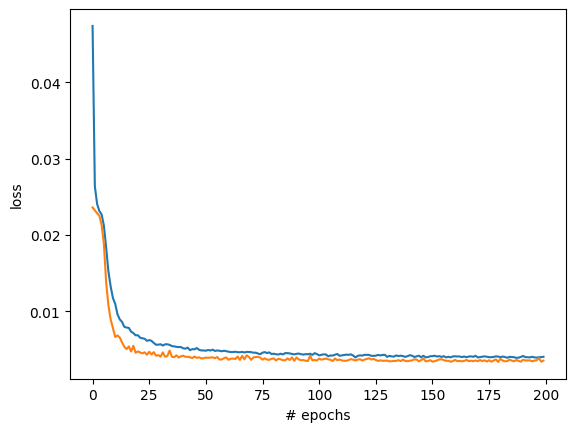

In [23]:
from matplotlib import pyplot as plt

plt.plot(model.history.history['loss'])
plt.plot(model.history.history['val_loss'])
plt.xlabel('# epochs')
plt.ylabel('loss')
plt.show()

In [ ]:
#print('actual inverse scaled:',scaler_target.inverse_transform(test_target[:10]).T)
#print('predicted inverse scaled:',scaler_target.inverse_transform(predicted_result[:10]).T)

In [29]:
#save already used scalling object algorithm to physical file
import joblib

joblib.dump(scaler_data,'scaler_data.sav')
joblib.dump(scaler_target,'scaler_target.sav')

['scaler_target.sav']